In [15]:
import pysam
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import argparse
import os
from collections import Counter

def plot_insertions(counts_df, total_genome_length, mode="mb", ax=None,):
    if ax is None:
        fig, ax = plt.subplots(figsize=(16, 6))
    count_df = counts_df.copy()
    # Plot Mb if mb specified as mode; else default to plotting bp
    if mode.lower() == "mb":
        position_plot_col = "position_mb"
        total_genome_length = total_genome_length / 1_000_000
    elif mode.lower() == "b":
        position_plot_col = "position"
    else:
        raise ValueError("Invalid mode for plotting! Options are mb for Mb scale or b for bp scale")
    # Set the count threshold for displaying labels.
    # A threshold of 0 will label every single point.
    label_threshold = 0
    # Filter the data to select points that meet the label threshold.
    labels_df = count_df[count_df['count'] >= label_threshold]
    print(f"  - Found {len(labels_df)} sites with counts >= {label_threshold} to label.")
    markerline, stemlines, baseline = ax.stem(
        count_df[position_plot_col],
        count_df['count'],
        linefmt='grey',
        markerfmt='o',
        basefmt=' '
    )
    plt.setp(markerline, 'markersize', 3, 'color', 'royalblue')

    # Add labels to stem plot
    for index, row in labels_df.iterrows():
        ax.text(
            x=row[position_plot_col] + 0.01,
            y=row['count'],
            s=f"{int(row['position'])}, {int(row['count'])}times",
            color='blue',
            fontsize=9
        )


    # Title and labels for ax
    ax.set_ylabel("Insertion Counts", fontsize=12)
    ax.set_ylim(bottom=0)

    # Optional x-axis limit
    if total_genome_length > 0:
        ax.set_xlim(left=0, right=total_genome_length)
    else:
        ax.set_xlim(left=0)
    return ax

def plot_triangle(target_coordinate, ax):
    # Plot a red triangle at the target site
    x_range = ax.get_xlim()[1] - ax.get_xlim()[0]
    triangle_width = x_range * 0.01
    # triangle_height = ax.get_ylim()[1] * 0.02  
    triangle_height = ax.get_ylim()[1] * 0.022
    # print(triangle_width, triangle_height, x_range)

    triangle = patches.Polygon(
        [[target_coordinate - triangle_width / 2, -triangle_height],
        [target_coordinate + triangle_width / 2, -triangle_height],
        [target_coordinate, 0]],
        transform=ax.transData,
        clip_on=False,
        color='red',
        alpha=1
    )
    ax.add_patch(triangle)

# def main():
# Set a professional style for the plots.
sns.set_style("whitegrid")


In [16]:
def parse_bam(wk_dir, title=""):
    alignment_file = os.path.join(wk_dir, "aligned_contigs.bam")
    assert os.path.exists(alignment_file), "Working dir must contain aligned_contigs.bam!"
    # out_dir = os.path.join(wk_dir, "plots")
    # if not os.path.exists(out_dir):
    #     os.makedirs(out_dir, exist_ok=True)

    # Set default title if not provided
    if not title:
        title = f"Insertion map for {alignment_file}"

    print(f"Step 2: Set alignment file to '{alignment_file}'")

    # --- Step 3: Data Processing (Extracting Insertion Sites and Genome Length) ---
    print("\nStep 3: Processing alignment file...")

    # Counter for tracking filtered reads.
    filter_counts = Counter({
        "unmapped": 0,
        "low_mapq": 0,
        "secondary": 0,
        "supplementary": 0,
    })
    insertion_sites, reference_names = [], []
    # total_genome_length = 0

    # Open the SAM/BAM file once to process reads and get header info.
    with pysam.AlignmentFile(alignment_file, "r") as samfile:
        # Get total genome length from the SAM/BAM header.
        if samfile.header.lengths:
            total_genome_lengths = dict(zip(samfile.header.references, samfile.header.lengths))
            print(f"Total genome lengths from header:")
            for genome, length in total_genome_lengths.items():
                print(f"\t{genome}: {length:,} bp")

        # Process all aligned reads in the file.
        for read in samfile.fetch(until_eof=True):
            # Check which filtering condition the read meets.
            if read.is_unmapped:
                filter_counts["unmapped"] += 1
                continue
            # MAPQ=0 often means a read maps to multiple locations.
            if read.mapping_quality == 0:
                filter_counts["low_mapq"] += 1
                continue
            # Secondary/supplementary alignments are alternative mappings for the same read.
            if read.is_secondary:
                filter_counts["secondary"] += 1
                continue
            if read.is_supplementary:
                filter_counts["supplementary"] += 1
                continue

            # For reads that pass the filters, get the 5' end position.
            pos = read.reference_end - 1 if read.is_reverse else read.reference_start
            insertion_sites.append(pos)
            reference_names.append(read.reference_name)

    # Report the filtering statistics.
    total_reads = sum(filter_counts.values()) + len(insertion_sites)
    print(f"Total reads processed: {total_reads:,}")
    for reason, count in filter_counts.items():
        print(f"  - {reason:14s}: {count:,} reads filtered out")
    print(f"  - Kept for analysis: {len(insertion_sites):,} reads")


    # --- Step 4: Data Aggregation and Formatting ---
    print("\nStep 4: Aggregating data...")

    positions_df = pd.DataFrame([insertion_sites, reference_names], index=['position', 'reference']).T

    # Convert to 1-based indexing
    positions_df["position"] += 1

    # Convert the results into a DataFrame for plotting.
    counts_df = pd.DataFrame(positions_df.groupby("reference")["position"].value_counts()).reset_index()

    # Add a column for plotting in Megabases (Mb).
    counts_df['position_mb'] = counts_df['position'] / 1_000_000
    # NOTE: The log10_count column is calculated but not used in the plot, so it's removed for clarity.
    print("  - Data aggregation complete.")
    return counts_df, positions_df, total_genome_lengths, title

Step 2: Set alignment file to '../data/CJ5Z9Y_v0/sample_3/aligned_contigs.bam'

Step 3: Processing alignment file...
Total genome lengths from header:
	pSES0099: 9,503 bp
	pSES0114: 142,357 bp
	gSES0128_insilico_wgs: 4,633,946 bp
Total reads processed: 500
  - unmapped      : 14 reads filtered out
  - low_mapq      : 0 reads filtered out
  - secondary     : 0 reads filtered out
  - supplementary : 0 reads filtered out
  - Kept for analysis: 486 reads

Step 4: Aggregating data...
  - Data aggregation complete.

Step 5: Creating genome-wide plots...
  - Found 2 sites with counts >= 0 to label.


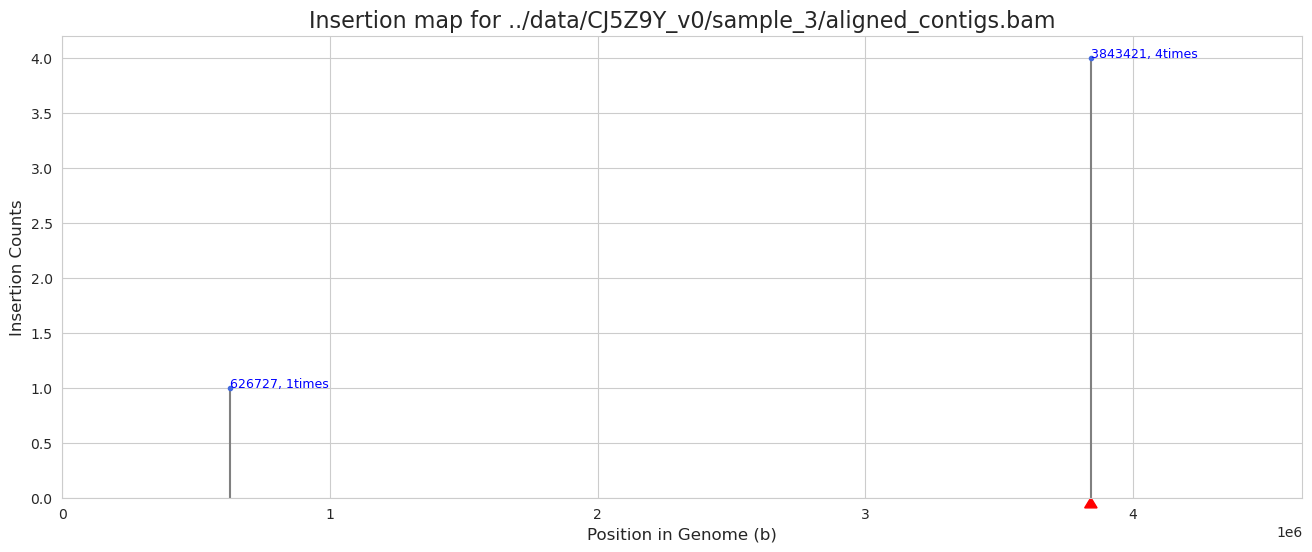

  - Found 1 sites with counts >= 0 to label.


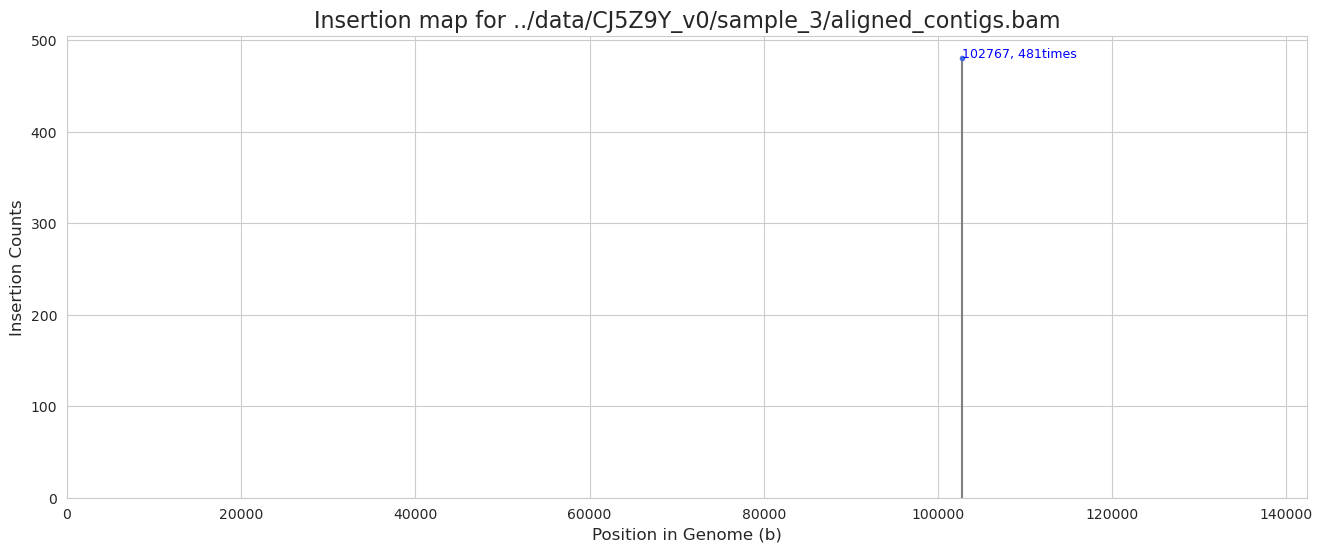

In [30]:
wk_dir = "../data/CJ5Z9Y_v0/sample_3"
counts_df, positions_df, total_genome_lengths, title = parse_bam(wk_dir)
target_coordinate = 3843421
print("\nStep 5: Creating genome-wide plots...")
##### Make the high level insertion map
reference_genome_name = "gSES0128_insilico_wgs"

for reference in counts_df["reference"].unique():

    ax = plot_insertions(
        counts_df[counts_df["reference"]==reference], 
        total_genome_lengths[reference], 
        mode="b")
    if reference == reference_genome_name:
        plot_triangle(target_coordinate, ax)
    if not title:
        title = f"Insertion map for {reference}"
    ax.set_title(title, fontsize=16)
    ax.set_xlabel("Position in Genome (b)", fontsize=12)
    # plt.title()
    plt.show()

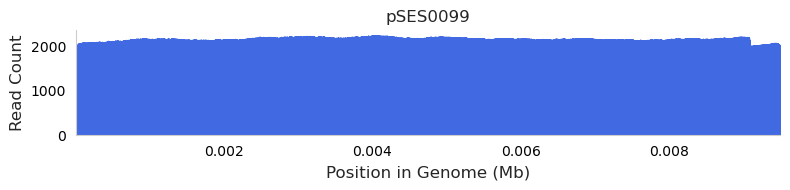

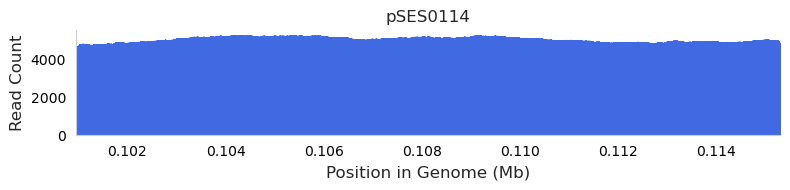

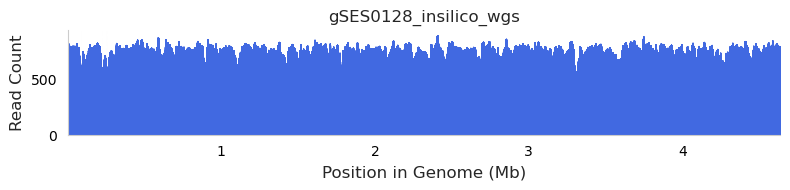

In [31]:
cov_df = pd.read_csv((os.path.join(wk_dir, "raw_reads_coverage.tsv")), sep="\t", header=None)
cov_df.columns=["chrom", "pos", "depth"]
cov_df["pos_mb"] = cov_df["pos"] / 1_000_000
# Subset to only reference genome
cov_df_ref = cov_df[cov_df["chrom"]==reference_genome_name]


for contig in cov_df["chrom"].unique():
    cov_df_contig = cov_df[cov_df["chrom"]==contig]
    # Plot coverage below insetion map
    fig, ax = plt.subplots(figsize=(8,2))
    ax.fill_between(cov_df_contig['pos_mb'], cov_df_contig['depth'], color='royalblue')
    ax.set_ylabel("Read Count", fontsize=12)
    ax.set_xlabel("Position in Genome (Mb)", fontsize=12)
    ax.set_ylim(bottom=0)
    ax.set_xlim(cov_df_contig["pos_mb"].min(), cov_df_contig["pos_mb"].max())
    ax.tick_params(
        direction='out',
        length=4,
        width=1,
        colors='black',
        grid_color='none',
        grid_alpha=0.5
    )
    sns.despine(ax=ax)
    ax.set_title(contig)

    # --- Layout adjustment ---
    plt.tight_layout()
    plt.show()

# OTHER: bRNA inheritance

In [ ]:
import argparse
import sys
import re
import numpy as np
from Bio import SeqIO
from Bio.Seq import reverse_complement
from Bio.SeqRecord import SeqRecord
from Bio.SeqFeature import SeqFeature, FeatureLocation, CompoundLocation
sys.path.append("../scripts/")
import find_brna
import copy
import os

class BridgeRNAReaction():
    def __init__(self, brna_path, other_sequence_paths, 
                 annotate_split_features=True):
        self.brna_path = brna_path
        self.other_sequence_paths = other_sequence_paths
        self.annotate_split_features = annotate_split_features
        self._process_brna()
        self._identify_sequences()

    def _process_brna(self):
        # Determines target and donor sites from bRNA in bRNA plasmid
        # NOTE: currently assumes there's only one sequence record in brna_plasmid
        self.brna_plasmid_record = SeqIO.read(self.brna_path, "genbank")
        target, donor = find_brna.find_target_donor_sites(self.brna_plasmid_record)
        self.target_site, self.lt, self.target_core, self.rt = target
        self.donor_site, self.ld, self.donor_core, self.rd = donor
        print(f"Using:\tTarget site: {self.target_site}\n\tDonor site: {self.donor_site}")

    # TODO: more descriptive error messages
    def _verify_unique_sites(self, target_matches, donor_matches):
        unique_donor_plasmid = len([i for i in donor_matches if i]) == 1
        unique_donor_site = sum([len(i) for i in donor_matches]) == 1
        unique_target_plasmid = len([i for i in target_matches if i]) == 1
        unique_target_site = sum([len(i) for i in target_matches]) == 1
        if not unique_donor_plasmid:
            raise ValueError(f"Expected exactly one donor plasmid match, but found {len(donor_matches)}.")

        if not unique_donor_site:
            total_donor_sites = sum(len(i) for i in donor_matches)
            raise ValueError(f"Expected exactly one donor site match, but found {total_donor_sites} total.")

        if not unique_target_plasmid:
            raise ValueError(f"Expected exactly one target plasmid match, but found {len(target_matches)}.")

        if not unique_target_site:
            total_target_sites = sum(len(i) for i in target_matches)
            raise ValueError(f"Expected exactly one target site match, but found {total_target_sites} total.")
        
    def _identify_sequences(self):
        # Read other sequence records
        sequence_paths = [self.brna_path]
        # Store all sequence records in additional sequence files
        other_sequence_records = []
        for filepath in self.other_sequence_paths:
            records = SeqIO.parse(filepath, "genbank")
            for record in records:
                    other_sequence_records.append(record)
                    sequence_paths.append(filepath)
        # other_sequence_records = [
        #     SeqIO.read(file, "genbank") for file in self.other_sequence_paths
        #     ]
        sequence_records = [self.brna_plasmid_record] + other_sequence_records
        seqs = [str(record.seq) for record in sequence_records]
        # Search all sequence records for target and donor sites
        target_matches = [
            self.find_matches(self.target_site, i) for i in seqs]
        donor_matches = [
            self.find_matches(self.donor_site, i) for i in seqs]
        self._verify_unique_sites(target_matches, donor_matches)
        # Determine rearrangement mode
        target_index = np.where([bool(i) for i in target_matches])[0].item()
        donor_index = np.where([bool(i) for i in donor_matches])[0].item()
        self.target_strand, self.target_start, self.target_end = target_matches[target_index][0]
        self.donor_strand, self.donor_start, self.donor_end = donor_matches[donor_index][0]

        self.target_file = os.path.splitext(os.path.basename(sequence_paths[target_index]))[0]
        
        print(f"Found target sequence: {self.target_file}\n\tstart: {self.target_start}\n\tend: {self.target_end}")
        self._find_split_sites()
        # Store target contig
        self.target_contig = sequence_records[target_index]
        self.annotate_site(
            record=self.target_contig, 
            site_start=self.target_start, 
            site_seq=self.target_site, 
            le_seq=self.lt, 
            re_seq=self.rt, 
            strand=self.target_strand, 
            mode="Target", 
            inplace=True)
        # Mode-specific preprocessing
        if target_index == donor_index:
            self.annotate_site(
                record=self.target_contig, 
                site_start=self.donor_start, 
                site_seq=self.donor_site, 
                le_seq=self.ld, 
                re_seq=self.rd, 
                strand=self.donor_strand, 
                mode="Donor", 
                inplace=True
                )
            if self.target_strand == self.donor_strand:
                self.mode = "excision"
            else:
                self.mode = "inversion"
        else:
            self.mode = "insertion"
            # Store separate donor record for insertions
            self.donor_file = os.path.splitext(os.path.basename(sequence_paths[donor_index]))[0]
            print(f"Found donor sequence: {self.donor_file}")
            self.donor_contig = sequence_records[donor_index]
            self.annotate_site(
                record=self.donor_contig, 
                site_start=self.donor_start, 
                site_seq=self.donor_site, 
                le_seq=self.ld, 
                re_seq=self.rd, 
                strand=self.donor_strand, 
                mode="Donor", 
                inplace=True
                )

    def _find_split_sites(self):
        # Store split sites
        if self.target_strand == 1:
            self.target_split_site = self.target_end - len(self.rt)
        else:
            self.target_split_site = self.target_start + len(self.rt)
        if self.donor_strand == 1:
            self.donor_split_site = self.donor_end - len(self.rt)
        else:
            self.donor_split_site = self.donor_start + len(self.rt)
        print(f"Split sites: DONOR: {self.donor_split_site} TARGET: {self.target_split_site}")
    
    def calculate_product(self):
        print(f"Calculating product in {self.mode} mode...")
        if self.mode == "insertion":
            result = self.calculate_insertion()
            return result
        elif self.mode == "excision":
            return self.calculate_excision()
        elif self.mode == "inversion":
            return self.calculate_inversion()
        else:
            raise ValueError("Invalid mode, no product calculated!")
    
    def calculate_insertion(self):
        if self.annotate_split_features:
            self.add_partial_sites(self.target_contig, self.target_split_site)
            self.add_partial_sites(self.target_contig, self.target_split_site)
            self.add_partial_sites(self.donor_contig, self.donor_split_site)
            self.add_partial_sites(self.donor_contig, self.donor_split_site)

        result = (
            self.target_contig[:self.target_split_site]
            + self.donor_contig[self.donor_split_site:]
            + self.donor_contig[:self.donor_split_site]
            + self.target_contig[self.target_split_site:]
        )
        prefix = (f"Predicted recombination product using target site = "
                  f"{self.target_site} and donor site = {self.donor_site}.\n"
                  f"Donor sequence info:\n{self.donor_contig.description}\n"
                  "Target sequence info:")
        result = self.transfer_metadata(
            old_record=self.target_contig,
            new_record=result,
            new_description_prefix=prefix
        )
        return [result]

    def calculate_excision(self):
        cut_points = [self.target_split_site, self.donor_split_site]
        upstream_cut = min(cut_points)
        downstream_cut = max(cut_points)
        if self.annotate_split_features:
            self.add_partial_sites(self.target_contig, upstream_cut)
            self.add_partial_sites(self.target_contig, downstream_cut)
        leftovers = (self.target_contig[:upstream_cut] 
                     + self.target_contig[downstream_cut:])
        excised = self.target_contig[upstream_cut:downstream_cut]
        # Transfer metadata
        common_prefix = (
            f"excision between {self.target_split_site+1} and "
            f"{self.donor_split_site+1} with target site = {self.target_site}, "
            f"donor site = {self.donor_site}\nDerived from:"
                      )
        leftovers = self.transfer_metadata(
            old_record=self.target_contig,
            new_record=leftovers,
            new_description_prefix=f"Backbone sequence from {common_prefix}"
        )
        excised = self.transfer_metadata(
            old_record=self.target_contig,
            new_record=excised,
            new_description_prefix=f"Excised sequence from {common_prefix}"
        )
        return [leftovers, excised]

    def calculate_inversion(self):
        cut_points = [self.target_split_site, self.donor_split_site]
        upstream_cut = min(cut_points)
        downstream_cut = max(cut_points)
        if self.annotate_split_features:
            self.add_partial_sites(self.target_contig, upstream_cut)
            self.add_partial_sites(self.target_contig, downstream_cut)
        inverted_record = (
            self.target_contig[:upstream_cut]
            + self.target_contig[upstream_cut:downstream_cut].reverse_complement()
            + self.target_contig[downstream_cut:]
        )
        # Transfer metadata
        inversion_prefix = (
            f"Inversion between {self.target_split_site+1} and "
            f"{self.donor_split_site+1} with target site = {self.target_site}, "
            f"donor site = {self.donor_site}\nDerived from:"
                      )
        inverted_record = self.transfer_metadata(
            old_record=self.target_contig, 
            new_record=inverted_record, 
            new_description_prefix=inversion_prefix)
        return [inverted_record]

    @classmethod    
    def find_matches(cls, site:str, seq:str):
        """
        Find matches for site in seq. 
        """
        # Find matches on positive and negative strands
        matches_pos_strand = [match for match in re.finditer(site, seq)]
        rc_contig = reverse_complement(seq)
        matches_neg_strand = [match for match in re.finditer(site, rc_contig)]
        matches = matches_pos_strand + matches_neg_strand
        match_strands = np.concatenate([
            np.ones_like(matches_pos_strand), np.ones_like(matches_neg_strand) * -1
            ])
        match_locations = []
        L = len(seq)
        for idx, match in enumerate(matches):
            strand = match_strands[idx]
            if strand == 1:
                site_start, site_end = match.start(), match.end()
            else:
                site_start, site_end = sorted([L - match.start(), L - match.end()])
            match_locations.append((strand, site_start, site_end))
        return match_locations

    @classmethod
    def annotate_site(
            cls, record, site_start, site_seq, le_seq, re_seq, strand=1, 
            mode="Target", inplace=False):
        """Adds left end, right end, and core annotations of either target or 
        donor site to a sequence record.

        Args:
            record (Bio.SeqRecord.SeqRecord): Record to annotate
            site_start (int): Start position of LE of site to annotate
            site_seq (str): Sequence of site to annotate
            le_seq (str): LE sequence
            re_seq (str): RE sequence
            strand (int): strand site is found on. Defaults to +1.
            mode (str, optional): Whether to annotate as Target or Donor site. 
                Defaults to "Target".
            inplace (bool, optional): Modify record inplace. Defaults to False.

        Returns:
            Bio.SeqRecord.SeqRecord: Input record with either Target or Donor
            site now annotated.
        """        
        allowed_modes = ["Target", "Donor"]
        assert mode in allowed_modes, f"mode must be one of: {allowed_modes}"
        colors = {
            "Target": "#00aeff",
            "Donor": "#ff8400",
            "Core": "#24951a",
        }
        # Extract indices of LT, RT relative to their respective contigs
        le_start, le_end = cls.find_partial_site(le_seq, site_seq, site_start, strand)
        re_start, re_end = cls.find_partial_site(re_seq, site_seq, site_start, strand)
        if strand == 1:
            core_start, core_end = sorted([le_end, re_start])
        else: 
            core_start, core_end = sorted([re_end, le_start])
        # print(mode, " LE: ", le_start, le_end, " RE: ", re_start, re_end, " Strand:", strand, "core:", core_end - core_start)
        # Annotate the partial sites
        # total_feat = SeqFeature(
        #     location=FeatureLocation(le_start, re_end, strand), 
        #     type="misc_feature", 
        #     qualifiers = {
        #         "label": f"{mode}",
        #         "ApEinfo_fwdcolor": colors[mode],
        #         "ApEinfo_revcolor": colors[mode],
        #         "note": f"color: {colors[mode]}"
        #     })
        direction = "RIGHT" if strand == 1 else "LEFT"
        le_feat = SeqFeature(
            location=FeatureLocation(le_start, le_end, strand), 
            type="gene", 
            qualifiers = {
                "label": f"{mode} LE",
                "ApEinfo_fwdcolor": colors[mode],
                "ApEinfo_revcolor": colors[mode],
                "note": f"color: {colors[mode]}; direction: {direction}"
            })
        re_feat = SeqFeature(
            location=FeatureLocation(re_start, re_end, strand), 
            type="gene", 
            qualifiers = {
                "label": f"{mode} RE",
                "ApEinfo_fwdcolor": colors[mode],
                "ApEinfo_revcolor": colors[mode],
                "note": f"color: {colors[mode]}; direction: {direction}"
            })
        core_feat = SeqFeature(
            location=FeatureLocation(core_start, core_end, strand), 
            type="gene", 
            qualifiers = {
                "label": f"{mode} Core",
                "ApEinfo_fwdcolor": colors["Core"],
                "ApEinfo_revcolor": colors["Core"],
                "note": f"color: {colors['Core']}; direction: {direction}"
            })
        # total_feat = SeqFeature(
        #     location=CompoundLocation([
        #         le_feat.location,
        #         core_feat.location,
        #         re_feat.location
        #     ]),
        #     type="misc_feature",
        #     qualifiers={
        #         "label": f"{mode}",
        #         "ApEinfo_fwdcolor": colors[mode],
        #         "ApEinfo_revcolor": colors[mode],
        #         "note": f"color: {colors[mode]}; direction: {direction}"
        #     },
        #     # sub_features=[le_feat, core_feat, re_feat]
        # )
        # new_feats = [le_feat, core_feat, re_feat, total_feat]
        new_feats = [le_feat, core_feat, re_feat,]
        if inplace:
            record.features += new_feats
        else:
            new_record = copy.deepcopy(record)
            new_record.features += new_feats
            return new_record

    @classmethod
    def find_partial_site(cls, part:str, site:str, contig_pos:int, strand=+1):
        """Finds locations of parts of a given site in relation to the location of
        the overall site in its native contig

        Args:
            part (str): Part of site. e.g. LT, RT, LD, RD
            site (str): Full sequence of target or donor site
            contig_pos (int): Start index of site in contig
            strand (int): Strand in which the site is found on the contig. 
                Must be either 1 or -1. Defaults to 1.
        Returns:
            (part_start, part_end): positions wrt the positive strand
        """    
        if strand == -1:
            part = reverse_complement(part)
            site = reverse_complement(site)
        part_start = site.index(part)
        part_end = part_start + len(part)
        # print(part_start, part_end, contig_pos, part, site)
        # part_start, part_end = find_matches(part, site, complement_search=False, 
        #                                     return_strand=False)
        part_start, part_end = contig_pos + part_start, contig_pos + part_end
        part_start, part_end = sorted([part_start, part_end])
        return part_start, part_end

    @classmethod
    def transfer_metadata(cls, old_record:SeqRecord, new_record:SeqRecord, 
                          new_description_prefix:str=""):
        """
        Transfer metadata from one SeqRecord to another, with an optional prefix
        added to the new record. 
        """
        new_description = f"{new_description_prefix}\n{old_record.description}"
        new_record.id = old_record.id
        new_record.name = old_record.name
        new_record.description = new_description
        new_record.annotations = old_record.annotations.copy()
        return new_record

    @classmethod
    def split_feature(cls, feature:SeqFeature, split_site:int):
        """Splits a sequence feature at a provided split site into an upstream
        and downstream component. 

        Args:
            feature (SeqFeature): Feature to split
            split_site (int): site to split at

        Returns:
            (upstream_feat, downstream_feat): New partial features
        """        
        start = int(feature.location.start)
        end = int(feature.location.end)
        strand = feature.location.strand
        original_label = (
            feature.qualifiers.get("label", [feature.type])[0]
            if feature.qualifiers else feature.type
        )
        # Upstream part
        upstream_loc = FeatureLocation(start, split_site, strand=strand)
        upstream_feat = SeqFeature(upstream_loc, type="misc_feature", qualifiers={
            "label": [f"UPSTREAM SPLIT: {original_label}"],
            "partial": ["true"],
            "ApEinfo_fwdcolor": ["#C0C0C0"], 
            "ApEinfo_revcolor": ["#C0C0C0"],
            # "ApEinfo_graphicformat": ["arrow_data {{}}"], # Hide by default
        })
        # Downstream part
        downstream_loc = FeatureLocation(split_site, end, strand=strand)
        downstream_feat = SeqFeature(downstream_loc, type="misc_feature", qualifiers={
            "label": [f"DOWNSTREAM SPLIT: {original_label}"],
            "partial": ["true"],
            "ApEinfo_fwdcolor": ["#C0C0C0"],
            "ApEinfo_revcolor": ["#C0C0C0"],
            # "ApEinfo_graphicformat": ["arrow_data {{}}"], # Hide by default
        })
        return (upstream_feat, downstream_feat)
    
    # TODO: add logic to properly split compound location features that overlap origin of circular record
    @classmethod
    def add_partial_sites(cls, record:SeqRecord, cut_site:int, 
                          inplace:bool=True):
        """Splits all features in a SeqRecord that pass through a certain spot
        by adding new features corresponding to the upstream and downstream
        portions of that feature.

        Args:
            record (SeqRecord): Record to add sites to.
            cut_site (int): Site at which to split
            inplace (bool, optional): Option to modify record inplace. Defaults to True.

        Returns:
            record (SeqRecord): Modified record, only returned if inplace=False
        """        
        if not inplace:
            record = copy.deepcopy(record)
        split_features = []
        for feature in record.features:
            if feature.type != "source":
                starts_before_cut_site = feature.location.start < cut_site
                ends_before_cut_site = feature.location.end <= cut_site
                if starts_before_cut_site & (not ends_before_cut_site):
                    split_feats = cls.split_feature(feature, cut_site)
                    split_features.extend(split_feats)
        record.features.extend(split_features)
        if not inplace:
            return record



In [26]:
class BridgeRNAPlasmid():
    def __init__(self, brna_path):
        self.brna_path = brna_path
        self._process_brna()

    def _process_brna(self):
        # Determines target and donor sites from bRNA in bRNA plasmid
        # NOTE: currently assumes there's only one sequence record in brna_plasmid
        self.brna_plasmid_record = SeqIO.read(self.brna_path, "genbank")
        target, donor = find_brna.find_target_donor_sites(self.brna_plasmid_record)
        self.target_site, self.lt, self.target_core, self.rt = target
        self.donor_site, self.ld, self.donor_core, self.rd = donor
        print(f"Using:\tTarget site: {self.target_site}\n\tDonor site: {self.donor_site}")

BridgeRNAPlasmid("../data/community_editing/plasmids/ggJRP0549.gbk")

Found bRNA on (+) strand, starting at 1055: AGTGCAGAGAAAATCGGCCAGTTTTCTCTGCCTGCAGTCCGCATGCCGTAGCCGCGGTTGGGTTCTAACCTGTGTATTACATTTATGCAGCGGACTGCCTTTCTCCCAAAGTGATAAACCGGACAGTATGATGGACCGGTTTTCCCGGTAATCCGTATTTACAACCGTGGTTTCACT
LTG: AGCCGCGGT
RTG: GTATTAC
Target site: AGCCGCGGTAATAC
    LT: AGCCGCG target core: GT RT: AATAC
LDG: ACAGTATG
RDG1: ACAAC
RDG2: AT
Donor site: ACAGTATGTTGTAT
    LD: ACAGTAT donor core: GT RD: TGTAT
Using:	Target site: AGCCGCGGTAATAC
	Donor site: ACAGTATGTTGTAT
